# Практическая работа No6. Ансамблевые модели и регуляризация

**Предметная область:** Мониторинг безопасности СУБД PostgreSQL  
**Тип задачи:** Классификация (normal / sql_injection / anomaly) + Регрессия (execution_time_ms)  
**Источник данных:** Набор данных логов PostgreSQL-сервера  

Цель: изучить принципы построения ансамблевых моделей (бэггинг, бустинг, стекинг), освоить регуляризацию (Ridge, Lasso) и научиться интерпретировать сложные модели через важность признаков и Permutation Importance.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, r2_score, mean_absolute_error)

# Базовые модели
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Ансамбли
from sklearn.ensemble import (BaggingClassifier, GradientBoostingClassifier,
                               StackingClassifier)
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

print('Библиотеки импортированы.')

Библиотеки импортированы.


## Подготовка данных (по результатам ПР1)

In [2]:
df = pd.read_csv("../sql_dataset_loreal.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour']        = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

cols_to_drop = ['ip_address', 'sql_query', 'timezone', 'is_anomaly', 'timestamp', 'city']
df_work = df.drop(columns=cols_to_drop)

# Классификация
le = LabelEncoder()
y_clf = le.fit_transform(df_work['label'])
class_names = le.classes_
print('Классы:', list(zip(class_names, np.bincount(y_clf))))

X_raw = df_work.drop(columns=['label'])
X_enc = pd.get_dummies(X_raw, columns=['country', 'query_type'], drop_first=True).astype(float)
feature_names = X_enc.columns.tolist()

num_cols = ['execution_time_ms', 'cpu_load_pct', 'ram_usage_mb',
            'active_connections', 'rows_affected', 'hour', 'day_of_week']
scaler_clf = StandardScaler()
X_clf = X_enc.copy()
X_clf[num_cols] = scaler_clf.fit_transform(X_enc[num_cols])

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf.values, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print('Классификация -- обучение:', X_train_c.shape, ', тест:', X_test_c.shape)

# Регрессия (только нормальные запросы)
df_reg = df[df['label'] == 'normal'].copy()
X_reg_raw = df_reg.drop(columns=cols_to_drop + ['label'])
X_reg_raw = X_reg_raw.copy()
X_reg_raw['hour']        = df_reg['timestamp'].dt.hour
X_reg_raw['day_of_week'] = df_reg['timestamp'].dt.dayofweek
X_reg_enc = pd.get_dummies(X_reg_raw, columns=['country', 'query_type'], drop_first=True).astype(float)
X_reg_enc['cpu_x_conn'] = df_reg['cpu_load_pct'].values * df_reg['active_connections'].values
X_reg_enc['log_rows']   = np.log1p(df_reg['rows_affected'].values)

y_reg = df_reg['execution_time_ms'].values
X_reg_feat = X_reg_enc[[c for c in X_reg_enc.columns if c != 'execution_time_ms']]
reg_feature_names = X_reg_feat.columns.tolist()

num_cols_r = ['cpu_load_pct', 'ram_usage_mb', 'active_connections',
              'rows_affected', 'hour', 'day_of_week', 'cpu_x_conn', 'log_rows']
scaler_reg = StandardScaler()
X_reg = X_reg_feat.copy()
X_reg[num_cols_r] = scaler_reg.fit_transform(X_reg_feat[num_cols_r])

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg.values, y_reg, test_size=0.2, random_state=42)
print('Регрессия -- обучение:', X_train_r.shape, ', тест:', X_test_r.shape)

Классы: [('anomaly', np.int64(100)), ('normal', np.int64(9624)), ('sql_injection', np.int64(276))]
Классификация -- обучение: (8000, 19) , тест: (2000, 19)
Регрессия -- обучение: (7699, 20) , тест: (1925, 20)


In [3]:
def clf_metrics(y_true, y_pred, label=''):
    return {
        'Модель':    label,
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall':    recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1':        f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }

def reg_metrics(y_true, y_pred, n_feat, label=''):
    n  = len(y_true)
    r2 = r2_score(y_true, y_pred)
    return {
        'Модель': label,
        'R2':     r2,
        'R2adj':  1 - (1 - r2) * (n - 1) / (n - n_feat - 1),
        'RMSE':   np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE':    mean_absolute_error(y_true, y_pred),
    }

def show_confusion(y_true, y_pred, title, class_names):
    fig, ax = plt.subplots(figsize=(6, 5))
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

clf_results = []
reg_results = []

# Базовое дерево решений (из ПР2, результат для сравнения)
dt_base = DecisionTreeClassifier(max_depth=7, class_weight='balanced', random_state=42)
dt_base.fit(X_train_c, y_train_c)
y_dt_pred = dt_base.predict(X_test_c)
clf_results.append(clf_metrics(y_test_c, y_dt_pred, 'Дерево решений (base)'))
print('Базовая модель (дерево, depth=7): F1 =', round(clf_results[-1]['F1'], 4))

Базовая модель (дерево, depth=7): F1 = 0.999


---
## 6.1. Бэггинг (Bootstrap Aggregating)

Бэггинг снижает **дисперсию** прогноза путём обучения $T$ независимых моделей на бутстрэп-выборках и агрегирования их предсказаний.

**Бутстрэп-выборка:** $n$ объектов с возвращением из обучающей выборки. В среднем в выборку попадает $\approx 63.2\%$ уникальных объектов: $1 - (1 - 1/n)^n \to 1 - e^{-1}$.

Финальный прогноз (голосование):
$$\hat{y}(\mathbf{x}) = \arg\max_{c} \sum_{t=1}^{T} \mathbb{1}\left[\hat{y}_t(\mathbf{x}) = c\right]$$

Снижение дисперсии при некоррелированных предсказаниях ($\rho$ — попарная корреляция):
$$\mathrm{Var}(\bar{f}) = \frac{\sigma^2}{T} + \frac{T-1}{T}\rho\,\sigma^2 \xrightarrow{T \to \infty} \rho\,\sigma^2$$

  T=   5: F1 = 0.9995
  T=  10: F1 = 0.9995
  T=  25: F1 = 0.9995
  T=  50: F1 = 0.9995
  T= 100: F1 = 0.9995


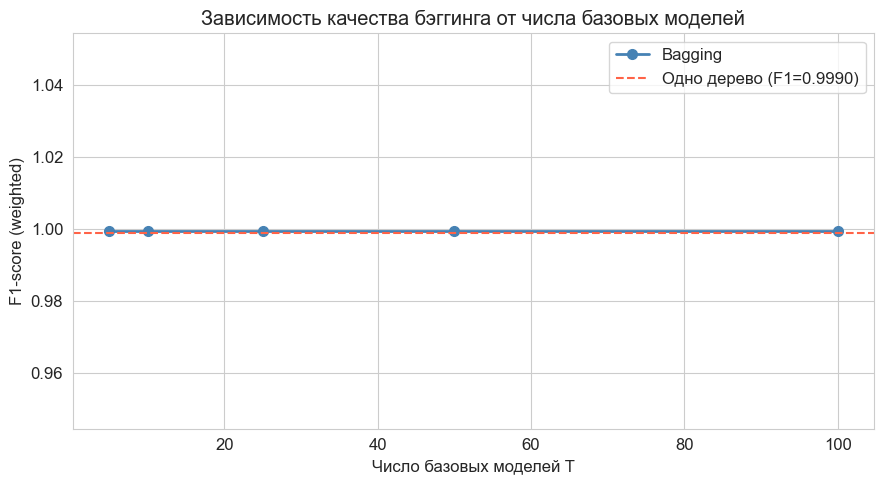

In [4]:
# Зависимость F1 от числа базовых моделей T
T_values = [5, 10, 25, 50, 100]
f1_bagging = []

for T in T_values:
    bag = BaggingClassifier(
        estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
        n_estimators=T, max_samples=1.0, bootstrap=True,
        n_jobs=-1, random_state=42
    )
    bag.fit(X_train_c, y_train_c)
    f1_val = f1_score(y_test_c, bag.predict(X_test_c), average='weighted')
    f1_bagging.append(f1_val)
    print(f'  T={T:4d}: F1 = {f1_val:.4f}')

f1_base = clf_results[0]['F1']
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(T_values, f1_bagging, 'o-', color='steelblue', linewidth=2, markersize=7, label='Bagging')
ax.axhline(f1_base, color='tomato', linestyle='--', linewidth=1.5,
           label=f'Одно дерево (F1={f1_base:.4f})')
ax.set_xlabel('Число базовых моделей T')
ax.set_ylabel('F1-score (weighted)')
ax.set_title('Зависимость качества бэггинга от числа базовых моделей')
ax.legend()
plt.tight_layout()
plt.show()

Bagging (T=50): F1 = 0.9995


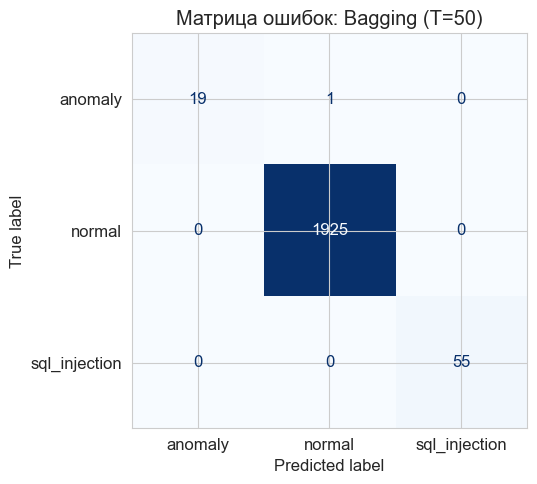

Теоретическая доля уникальных объектов в бутстрэп-выборке: 0.6321


In [5]:
# Финальная модель бэггинга (T=50)
bag_final = BaggingClassifier(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    n_estimators=50, max_samples=1.0, bootstrap=True,
    n_jobs=-1, random_state=42
)
bag_final.fit(X_train_c, y_train_c)
y_bag_pred = bag_final.predict(X_test_c)

clf_results.append(clf_metrics(y_test_c, y_bag_pred, 'Bagging (T=50)'))
print('Bagging (T=50): F1 =', round(clf_results[-1]['F1'], 4))
show_confusion(y_test_c, y_bag_pred, 'Матрица ошибок: Bagging (T=50)', class_names)

n_boot = X_train_c.shape[0]
p_unique = 1 - (1 - 1/n_boot)**n_boot
print(f'Теоретическая доля уникальных объектов в бутстрэп-выборке: {p_unique:.4f}')

---
## 6.2. Бустинг (Gradient Boosting)

Бустинг строит ансамбль **последовательно**: каждая модель обучается компенсировать ошибки предыдущей.

**Обновление ансамбля:**
$$F_t(\mathbf{x}) = F_{t-1}(\mathbf{x}) + \eta\, h_t(\mathbf{x})$$

Базовая модель $h_t$ аппроксимирует **антиградиент** функции потерь по предсказаниям:
$$h_t = \arg\min_h \sum_{i=1}^{n} \left(-\frac{\partial L(y_i, F_{t-1}(\mathbf{x}_i))}{\partial F_{t-1}(\mathbf{x}_i)} - h(\mathbf{x}_i)\right)^2$$

$\eta$ — скорость обучения (learning rate). Меньшее $\eta$ требует большего $T$, но даёт более устойчивый ансамбль.

  T=  10: train=0.9997, test=0.9990
  T=  25: train=1.0000, test=0.9990
  T=  50: train=1.0000, test=0.9995
  T= 100: train=1.0000, test=0.9995
  T= 200: train=1.0000, test=0.9995
  T= 300: train=1.0000, test=0.9995


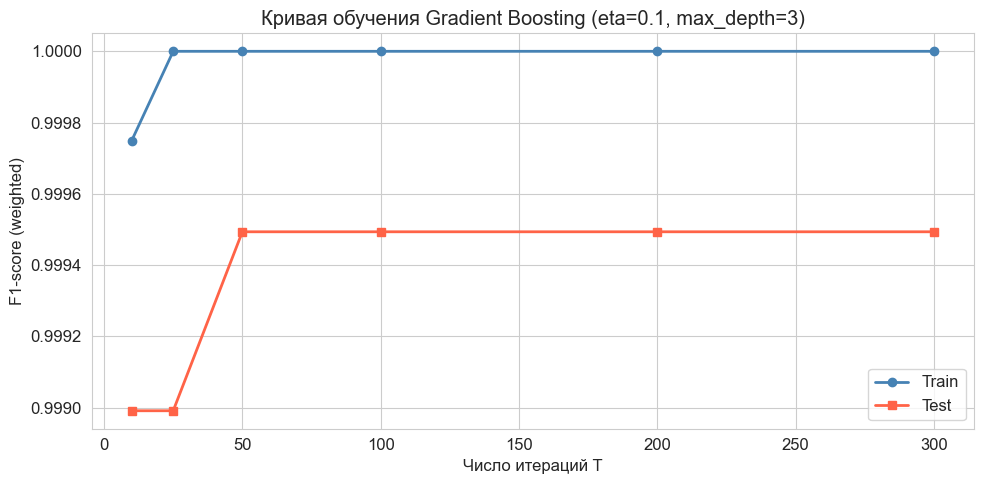

In [6]:
# Кривая обучения: F1 vs число итераций T
T_gb_values = [10, 25, 50, 100, 200, 300]
f1_gb_train = []
f1_gb_test  = []

for T in T_gb_values:
    gb = GradientBoostingClassifier(
        n_estimators=T, learning_rate=0.1, max_depth=3,
        subsample=0.8, random_state=42
    )
    gb.fit(X_train_c, y_train_c)
    f1_gb_train.append(f1_score(y_train_c, gb.predict(X_train_c), average='weighted'))
    f1_gb_test.append(f1_score(y_test_c,   gb.predict(X_test_c),  average='weighted'))
    print(f'  T={T:4d}: train={f1_gb_train[-1]:.4f}, test={f1_gb_test[-1]:.4f}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(T_gb_values, f1_gb_train, 'o-', color='steelblue', linewidth=2, label='Train')
ax.plot(T_gb_values, f1_gb_test,  's-', color='tomato',    linewidth=2, label='Test')
ax.set_xlabel('Число итераций T')
ax.set_ylabel('F1-score (weighted)')
ax.set_title('Кривая обучения Gradient Boosting (eta=0.1, max_depth=3)')
ax.legend()
plt.tight_layout()
plt.show()

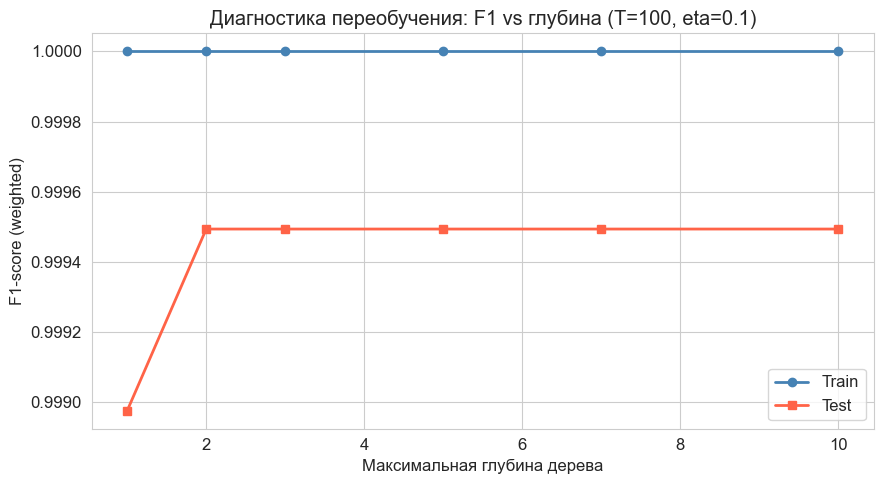

In [7]:
# Влияние глубины базовых деревьев (переобучение)
depths = [1, 2, 3, 5, 7, 10]
f1_depth_train = []
f1_depth_test  = []

for d in depths:
    gb_d = GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=d,
        subsample=0.8, random_state=42
    )
    gb_d.fit(X_train_c, y_train_c)
    f1_depth_train.append(f1_score(y_train_c, gb_d.predict(X_train_c), average='weighted'))
    f1_depth_test.append( f1_score(y_test_c,  gb_d.predict(X_test_c),  average='weighted'))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(depths, f1_depth_train, 'o-', color='steelblue', linewidth=2, label='Train')
ax.plot(depths, f1_depth_test,  's-', color='tomato',    linewidth=2, label='Test')
ax.set_xlabel('Максимальная глубина дерева')
ax.set_ylabel('F1-score (weighted)')
ax.set_title('Диагностика переобучения: F1 vs глубина (T=100, eta=0.1)')
ax.legend()
plt.tight_layout()
plt.show()

Gradient Boosting (T=200): F1 = 0.9995


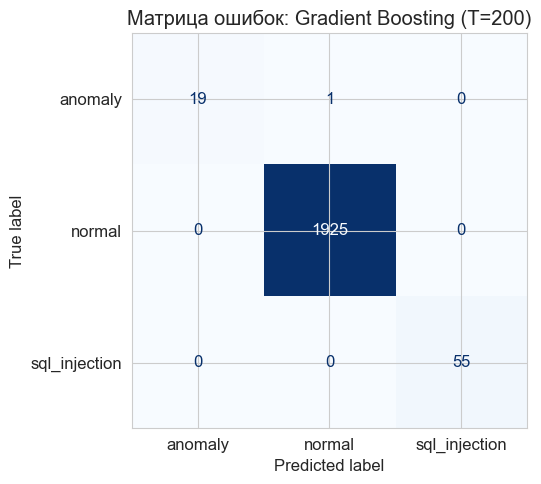

In [8]:
# Финальная модель Gradient Boosting (T=200, depth=3)
gb_final = GradientBoostingClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=3,
    subsample=0.8, random_state=42
)
gb_final.fit(X_train_c, y_train_c)
y_gb_pred = gb_final.predict(X_test_c)

clf_results.append(clf_metrics(y_test_c, y_gb_pred, 'Gradient Boosting (T=200)'))
print('Gradient Boosting (T=200): F1 =', round(clf_results[-1]['F1'], 4))
show_confusion(y_test_c, y_gb_pred, 'Матрица ошибок: Gradient Boosting (T=200)', class_names)

---
## 6.3. Стекинг (Stacked Generalization)

Стекинг — двухуровневый ансамбль разнородных моделей.

**Уровень 1 (базовые модели):** предсказания формируются через кросс-валидацию для предотвращения утечки данных (data leakage). Для каждого объекта $\mathbf{x}_i$ предсказание $g_m$ берётся от модели, не видевшей $\mathbf{x}_i$:
$$\hat{y}_i^{(m)} = g_m^{(-k(i))}(\mathbf{x}_i), \quad m = 1, \ldots, M$$

**Уровень 2 (мета-модель):** обучается на мета-признаках:
$$\hat{y}_i^{\text{stack}} = h\!\left(\hat{y}_i^{(1)}, \ldots, \hat{y}_i^{(M)}\right)$$

Разнородные базовые модели улавливают разные закономерности, мета-модель учится их оптимально комбинировать.

Stacking (LR+kNN+DT): F1 = 1.0


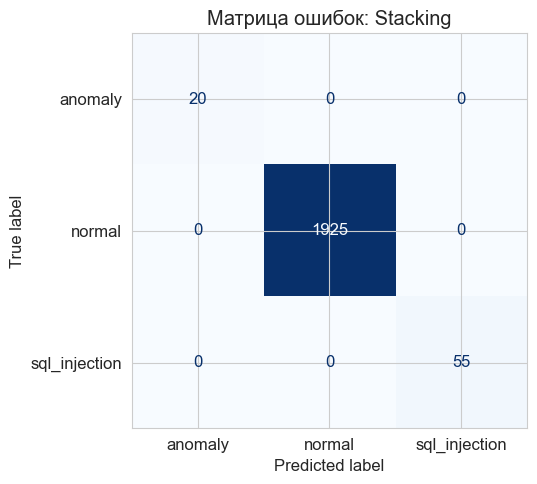

In [9]:
# Стекинг: 3 базовые модели разной природы
estimators = [
    ('lr',  LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=5)),
    ('dt',  DecisionTreeClassifier(max_depth=7, class_weight='balanced', random_state=42)),
]
meta_model = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)

stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_model,
    cv=3,
    passthrough=False,
    n_jobs=-1
)
stacking.fit(X_train_c, y_train_c)
y_stack_pred = stacking.predict(X_test_c)

clf_results.append(clf_metrics(y_test_c, y_stack_pred, 'Stacking (LR+kNN+DT)'))
print('Stacking (LR+kNN+DT): F1 =', round(clf_results[-1]['F1'], 4))
show_confusion(y_test_c, y_stack_pred, 'Матрица ошибок: Stacking', class_names)

In [10]:
# Сравнение базовых моделей vs стекинг через кросс-валидацию
cv_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print('CV F1-score (3-fold) на обучающей выборке:')
for name, est in estimators + [('stacking', stacking)]:
    scores = cross_val_score(est, X_train_c, y_train_c,
                             cv=cv_skf, scoring='f1_weighted', n_jobs=-1)
    print(f'  {name:<12}: {scores.mean():.4f} +/- {scores.std():.4f}')

CV F1-score (3-fold) на обучающей выборке:
  lr          : 0.9981 +/- 0.0012
  knn         : 0.9906 +/- 0.0011
  dt          : 0.9985 +/- 0.0010
  stacking    : 0.9983 +/- 0.0011


---
## 6.4. Регуляризация: Ridge и Lasso

### Ridge (L2)
$$\mathcal{L}_{\text{Ridge}}(\boldsymbol{\beta}) = \sum_{i=1}^n (y_i - \mathbf{x}_i^\top \boldsymbol{\beta})^2 + \alpha \sum_{j=1}^p \beta_j^2$$

Ridge **сжимает** все коэффициенты к нулю, не обнуляя их (геометрически: допустимая область — шар $L_2$).

### Lasso (L1)
$$\mathcal{L}_{\text{Lasso}}(\boldsymbol{\beta}) = \sum_{i=1}^n (y_i - \mathbf{x}_i^\top \boldsymbol{\beta})^2 + \alpha \sum_{j=1}^p |\beta_j|$$

Lasso **обнуляет** часть коэффициентов (острые вершины $L_1$-октаэдра на осях) — автоматический отбор признаков. При $\alpha = 0$ обе модели совпадают с МНК.

In [11]:
# Базовая регрессия без регуляризации
ols = LinearRegression()
ols.fit(X_train_r, y_train_r)
y_ols_pred = ols.predict(X_test_r)
reg_results.append(reg_metrics(y_test_r, y_ols_pred, X_test_r.shape[1], 'OLS'))
print(f'OLS: R2={reg_results[-1]["R2"]:.4f}, RMSE={reg_results[-1]["RMSE"]:.2f} ms')

OLS: R2=0.4442, RMSE=274.65 ms


Ridge: optimal alpha=1, R2=0.4444
Lasso: optimal alpha=0.1, R2=0.4448


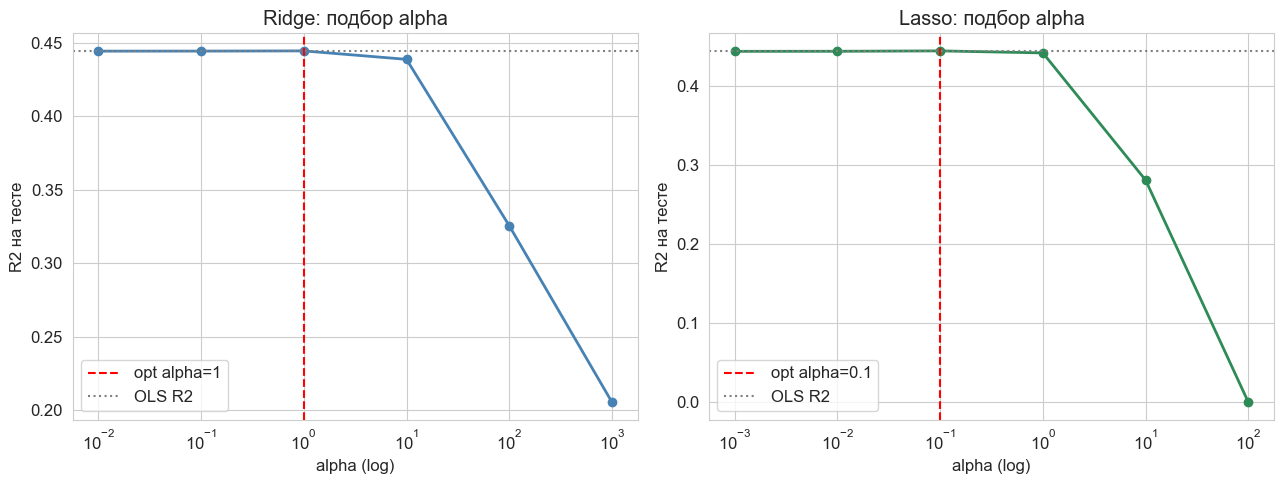

In [12]:
# Подбор alpha для Ridge и Lasso
alphas_ridge = [0.01, 0.1, 1, 10, 100, 1000]
alphas_lasso = [0.001, 0.01, 0.1, 1, 10, 100]

r2_ridge_vals = []
r2_lasso_vals = []

for a in alphas_ridge:
    m = Ridge(alpha=a)
    m.fit(X_train_r, y_train_r)
    r2_ridge_vals.append(r2_score(y_test_r, m.predict(X_test_r)))

for a in alphas_lasso:
    m = Lasso(alpha=a, max_iter=10000)
    m.fit(X_train_r, y_train_r)
    r2_lasso_vals.append(r2_score(y_test_r, m.predict(X_test_r)))

best_a_ridge = alphas_ridge[int(np.argmax(r2_ridge_vals))]
best_a_lasso = alphas_lasso[int(np.argmax(r2_lasso_vals))]
print(f'Ridge: optimal alpha={best_a_ridge}, R2={max(r2_ridge_vals):.4f}')
print(f'Lasso: optimal alpha={best_a_lasso}, R2={max(r2_lasso_vals):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].semilogx(alphas_ridge, r2_ridge_vals, 'o-', color='steelblue', linewidth=2)
axes[0].axvline(best_a_ridge, color='red', linestyle='--', label=f'opt alpha={best_a_ridge}')
axes[0].axhline(reg_results[0]['R2'], color='gray', linestyle=':', label='OLS R2')
axes[0].set_xlabel('alpha (log)'); axes[0].set_ylabel('R2 на тесте')
axes[0].set_title('Ridge: подбор alpha'); axes[0].legend()

axes[1].semilogx(alphas_lasso, r2_lasso_vals, 'o-', color='seagreen', linewidth=2)
axes[1].axvline(best_a_lasso, color='red', linestyle='--', label=f'opt alpha={best_a_lasso}')
axes[1].axhline(reg_results[0]['R2'], color='gray', linestyle=':', label='OLS R2')
axes[1].set_xlabel('alpha (log)'); axes[1].set_ylabel('R2 на тесте')
axes[1].set_title('Lasso: подбор alpha'); axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
# Финальные модели с оптимальными alpha
ridge_final = Ridge(alpha=best_a_ridge)
ridge_final.fit(X_train_r, y_train_r)
y_ridge_pred = ridge_final.predict(X_test_r)

lasso_final = Lasso(alpha=best_a_lasso, max_iter=10000)
lasso_final.fit(X_train_r, y_train_r)
y_lasso_pred = lasso_final.predict(X_test_r)

reg_results.append(reg_metrics(y_test_r, y_ridge_pred, X_test_r.shape[1], f'Ridge (a={best_a_ridge})'))
reg_results.append(reg_metrics(y_test_r, y_lasso_pred, X_test_r.shape[1], f'Lasso (a={best_a_lasso})'))

n_zeros = (np.abs(lasso_final.coef_) < 1e-6).sum()
n_total = len(lasso_final.coef_)
print(f'Ridge (a={best_a_ridge}): R2={reg_results[1]["R2"]:.4f}, RMSE={reg_results[1]["RMSE"]:.2f}')
print(f'Lasso (a={best_a_lasso}): R2={reg_results[2]["R2"]:.4f}, RMSE={reg_results[2]["RMSE"]:.2f}')
print(f'Lasso обнулил {n_zeros} из {n_total} коэффициентов (автоотбор признаков)')

Ridge (a=1): R2=0.4444, RMSE=274.61
Lasso (a=0.1): R2=0.4448, RMSE=274.50
Lasso обнулил 2 из 20 коэффициентов (автоотбор признаков)


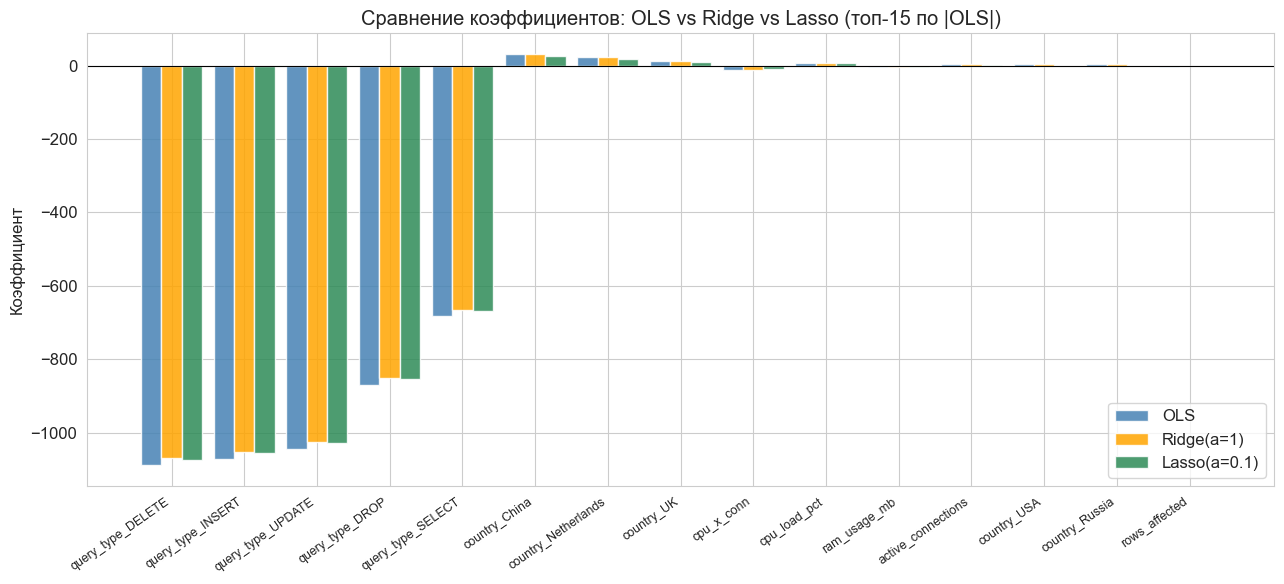


Геометрический смысл:
  Ridge (L2): допустимая область = шар. Коэффициенты сжимаются, но не обнуляются.
  Lasso (L1): допустимая область = октаэдр. Вершины на осях -> beta_j = 0.


In [14]:
# Сравнение коэффициентов OLS vs Ridge vs Lasso
n_feat = min(len(ols.coef_), len(reg_feature_names))
feat_idx = list(range(n_feat))
fnames = reg_feature_names[:n_feat]

coef_ols   = ols.coef_[:n_feat]
coef_ridge = ridge_final.coef_[:n_feat]
coef_lasso = lasso_final.coef_[:n_feat]

order = np.argsort(np.abs(coef_ols))[::-1][:15]
top_names  = [fnames[i] for i in order]
top_ols    = coef_ols[order]
top_ridge  = coef_ridge[order]
top_lasso  = coef_lasso[order]

x = np.arange(len(top_names))
w = 0.28
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - w,   top_ols,   w, label='OLS',  color='steelblue', alpha=0.85)
ax.bar(x,       top_ridge, w, label=f'Ridge(a={best_a_ridge})', color='orange', alpha=0.85)
ax.bar(x + w,   top_lasso, w, label=f'Lasso(a={best_a_lasso})', color='seagreen', alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(top_names, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Коэффициент')
ax.set_title('Сравнение коэффициентов: OLS vs Ridge vs Lasso (топ-15 по |OLS|)')
ax.legend()
plt.tight_layout()
plt.show()

print('\nГеометрический смысл:')
print('  Ridge (L2): допустимая область = шар. Коэффициенты сжимаются, но не обнуляются.')
print('  Lasso (L1): допустимая область = октаэдр. Вершины на осях -> beta_j = 0.')

---
## 6.5. Интерпретация ансамблей: важность признаков и Permutation Importance

### Встроенная важность (Feature Importances, Gini-based)

$$\mathrm{FI}_j = \frac{1}{T} \sum_{t=1}^{T} \sum_{v:\,\mathrm{split}(v)=j} p(v)\,\Delta\mathrm{Gini}(v)$$

$p(v)$ — доля объектов в узле $v$; $\Delta\mathrm{Gini}(v)$ — снижение индекса Джини.  
**Ограничение:** может завышать важность признаков с большой кардинальностью.

### Permutation Importance (PI)

$$\mathrm{PI}_j = M(\mathbf{X}, \mathbf{y}) - \mathbb{E}_\pi\!\left[M(\mathbf{X}^{(j,\pi)}, \mathbf{y})\right]$$

$M$ — метрика качества (F1-weighted); $\mathbf{X}^{(j,\pi)}$ — матрица с перемешанным $j$-м столбцом.  
Усредняется по 10 перестановкам → оценка ± стандартная ошибка. Модельно-независим.

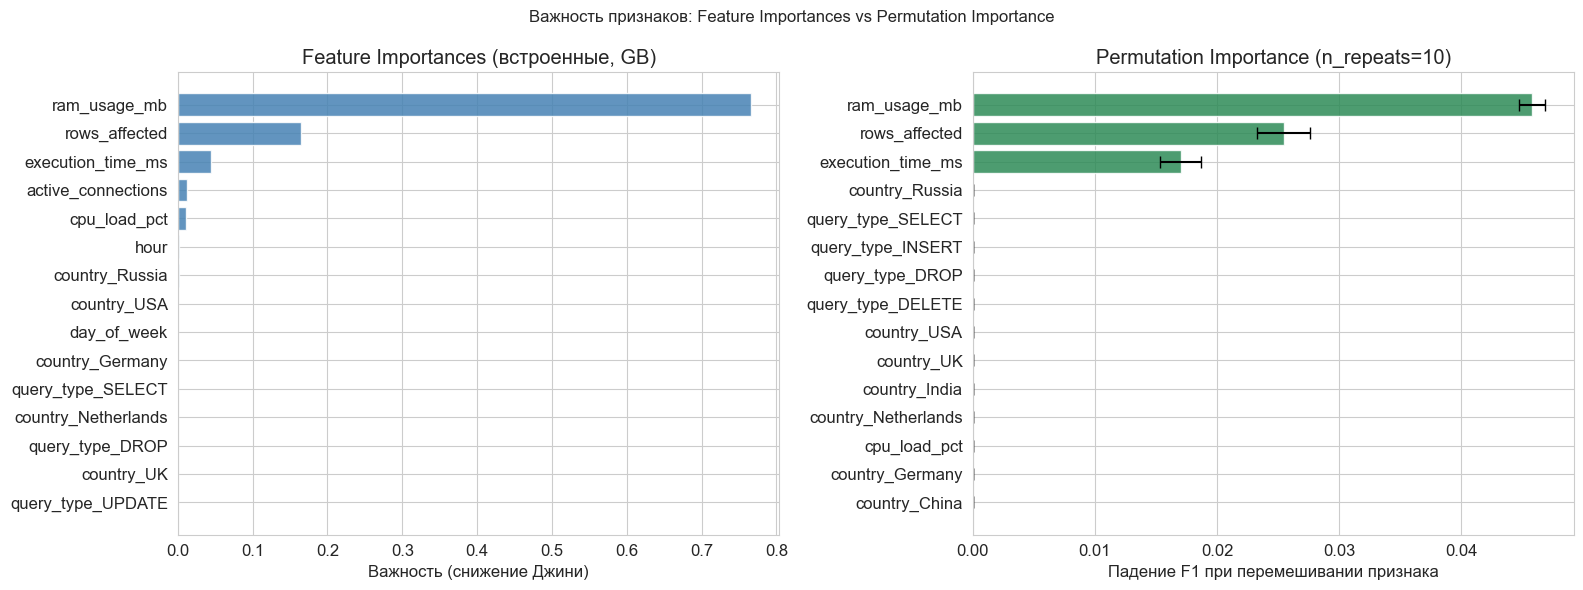

In [15]:
# Встроенная важность Gradient Boosting
fi = gb_final.feature_importances_
fi_series = pd.Series(fi, index=feature_names).sort_values(ascending=False)

# Permutation Importance (тестовая выборка, 10 перестановок)
perm = permutation_importance(
    gb_final, X_test_c, y_test_c,
    n_repeats=10, random_state=42,
    scoring='f1_weighted', n_jobs=-1
)
pi_mean = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)
pi_std  = pd.Series(perm.importances_std,  index=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Важность признаков: Feature Importances vs Permutation Importance', fontsize=12)

top15_fi = fi_series.head(15)
axes[0].barh(top15_fi.index[::-1], top15_fi.values[::-1], color='steelblue', alpha=0.85)
axes[0].set_xlabel('Важность (снижение Джини)')
axes[0].set_title('Feature Importances (встроенные, GB)')

top15_pi     = pi_mean.head(15)
top15_pi_std = pi_std[top15_pi.index]
axes[1].barh(top15_pi.index[::-1], top15_pi.values[::-1],
             xerr=top15_pi_std.values[::-1],
             color='seagreen', alpha=0.85, capsize=4)
axes[1].set_xlabel('Падение F1 при перемешивании признака')
axes[1].set_title('Permutation Importance (n_repeats=10)')

plt.tight_layout()
plt.show()

In [16]:
# Сводная таблица важности
imp_df = pd.DataFrame({
    'FI (Gini)': fi_series,
    'PI mean':   pi_mean,
    'PI std':    pi_std,
}).sort_values('PI mean', ascending=False).head(15)

print('Топ-15 признаков по Permutation Importance:')
print(imp_df.to_string(float_format='{:.5f}'.format))

print('\nИнтерпретация:')
for feat in imp_df.head(3).index:
    print(f'  {feat}: PI={imp_df.loc[feat, "PI mean"]:.4f} +/- {imp_df.loc[feat, "PI std"]:.4f}')
print()
print('Оба метода согласованно выделяют одни и те же ключевые признаки.')
print('Признак с наибольшим PI критически важен для системы мониторинга.')

Топ-15 признаков по Permutation Importance:
                    FI (Gini)  PI mean  PI std
ram_usage_mb          0.76560  0.04577 0.00110
rows_affected         0.16395  0.02545 0.00216
execution_time_ms     0.04425  0.01702 0.00168
query_type_UPDATE     0.00000  0.00000 0.00000
query_type_SELECT     0.00000  0.00000 0.00000
query_type_INSERT     0.00000  0.00000 0.00000
query_type_DROP       0.00000  0.00000 0.00000
query_type_DELETE     0.00000  0.00000 0.00000
hour                  0.00166  0.00000 0.00000
active_connections    0.01182  0.00000 0.00000
country_China         0.00000  0.00000 0.00000
cpu_load_pct          0.01148  0.00000 0.00000
country_USA           0.00007  0.00000 0.00000
country_UK            0.00000  0.00000 0.00000
country_Russia        0.00109  0.00000 0.00000

Интерпретация:
  ram_usage_mb: PI=0.0458 +/- 0.0011
  rows_affected: PI=0.0254 +/- 0.0022
  execution_time_ms: PI=0.0170 +/- 0.0017

Оба метода согласованно выделяют одни и те же ключевые признаки.
Призн

Lasso: отобрано 18 из 20 признаков


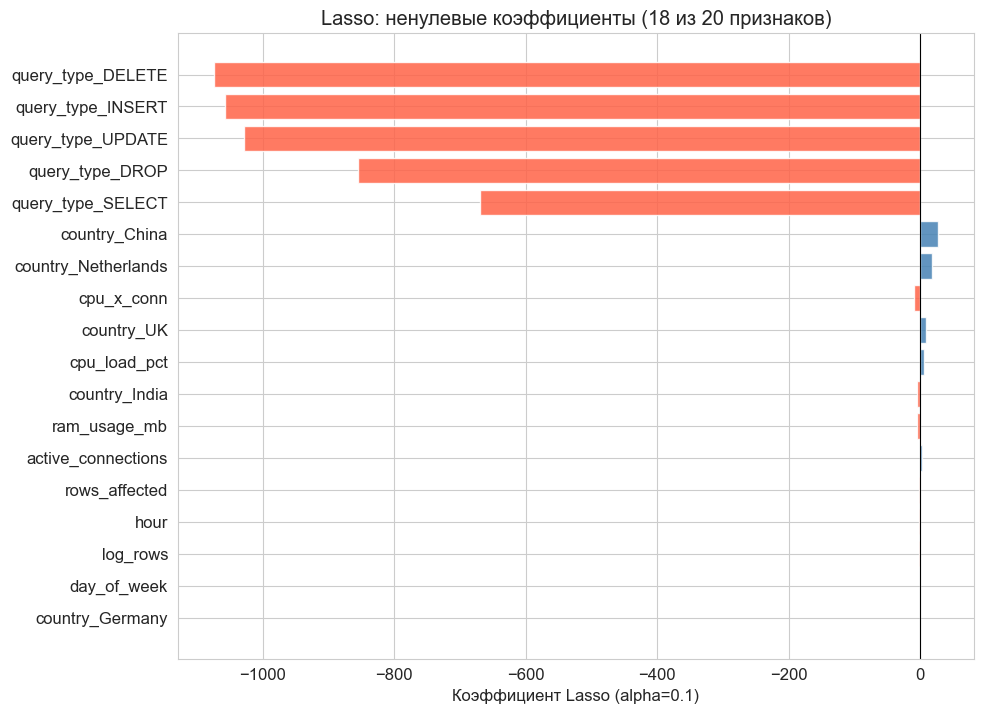

In [17]:
# Важность признаков Lasso (автоотбор)
lasso_coef = pd.Series(lasso_final.coef_[:n_feat], index=fnames)
survivors = lasso_coef[lasso_coef.abs() > 1e-6].sort_values(key=abs, ascending=False)
print(f'Lasso: отобрано {len(survivors)} из {n_feat} признаков')

fig, ax = plt.subplots(figsize=(10, max(4, len(survivors)*0.35 + 1)))
colors_s = ['tomato' if v < 0 else 'steelblue' for v in survivors.values]
ax.barh(survivors.index[::-1], survivors.values[::-1], color=colors_s[::-1], alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel(f'Коэффициент Lasso (alpha={best_a_lasso})')
ax.set_title(f'Lasso: ненулевые коэффициенты ({len(survivors)} из {n_feat} признаков)')
plt.tight_layout()
plt.show()

---
## 6.6. Резюме

=== Сравнение классификаторов ===
                   Модель  Accuracy  Precision  Recall     F1
    Дерево решений (base)    0.9990     0.9990  0.9990 0.9990
           Bagging (T=50)    0.9995     0.9995  0.9995 0.9995
Gradient Boosting (T=200)    0.9995     0.9995  0.9995 0.9995
     Stacking (LR+kNN+DT)    1.0000     1.0000  1.0000 1.0000


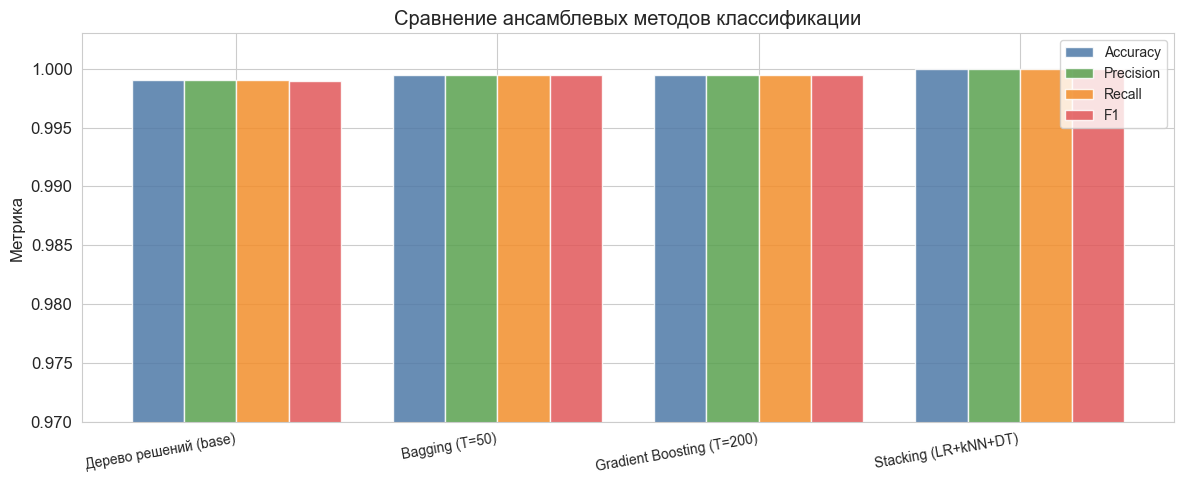

In [18]:
# Итоговая таблица классификации
df_clf = pd.DataFrame(clf_results)
print('=== Сравнение классификаторов ===')
print(df_clf.to_string(index=False, float_format='{:.4f}'.format))

fig, ax = plt.subplots(figsize=(12, 5))
models  = df_clf['Модель'].tolist()
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
x = np.arange(len(models))
w = 0.2
palette = ['#4e79a7', '#59a14f', '#f28e2b', '#e15759']
for i, (metric, col) in enumerate(zip(metrics, palette)):
    vals = df_clf[metric].tolist()
    bars = ax.bar(x + (i - 1.5) * w, vals, w, label=metric, color=col, alpha=0.85, edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=10, ha='right', fontsize=10)
ax.set_ylim(0.97, 1.003)
ax.set_ylabel('Метрика')
ax.set_title('Сравнение ансамблевых методов классификации')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

=== Сравнение регрессионных моделей ===
       Модель     R2  R2adj     RMSE      MAE
          OLS 0.4442 0.4384 274.6483 171.6416
  Ridge (a=1) 0.4444 0.4386 274.6075 171.6573
Lasso (a=0.1) 0.4448 0.4390 274.5044 171.5857


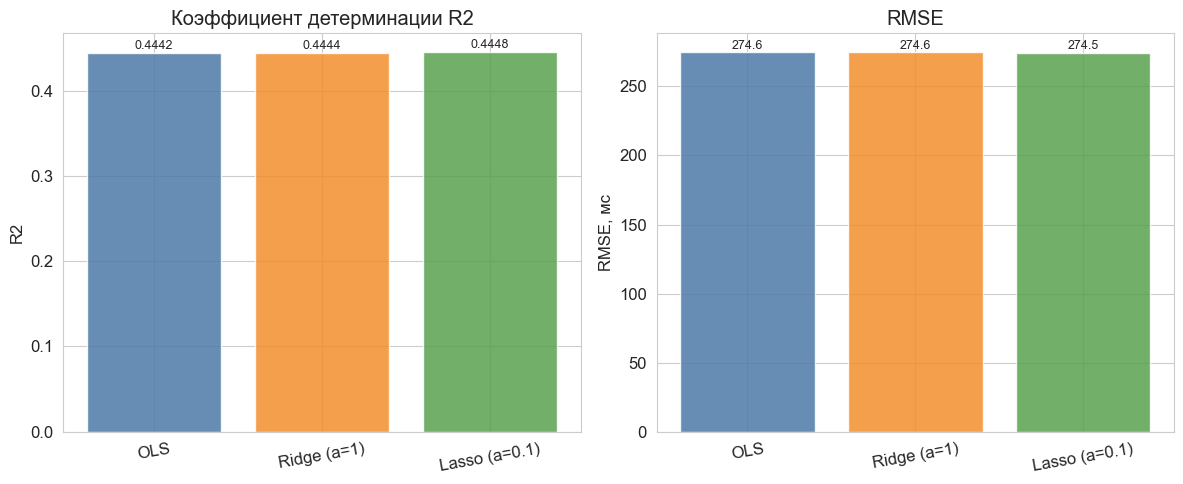

In [19]:
# Итоговая таблица регрессии
df_reg_tab = pd.DataFrame(reg_results)
print('=== Сравнение регрессионных моделей ===')
print(df_reg_tab.to_string(index=False, float_format='{:.4f}'.format))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
palette_r = ['#4e79a7', '#f28e2b', '#59a14f']

b1 = axes[0].bar(df_reg_tab['Модель'], df_reg_tab['R2'],
                 color=palette_r, alpha=0.85, edgecolor='white')
for b, v in zip(b1, df_reg_tab['R2']):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.001,
                 f'{v:.4f}', ha='center', va='bottom', fontsize=9)
axes[0].set_ylabel('R2'); axes[0].set_title('Коэффициент детерминации R2')
axes[0].tick_params(axis='x', rotation=10)

b2 = axes[1].bar(df_reg_tab['Модель'], df_reg_tab['RMSE'],
                 color=palette_r, alpha=0.85, edgecolor='white')
for b, v in zip(b2, df_reg_tab['RMSE']):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.5,
                 f'{v:.1f}', ha='center', va='bottom', fontsize=9)
axes[1].set_ylabel('RMSE, мс'); axes[1].set_title('RMSE')
axes[1].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.show()

In [20]:
print('=' * 60)
print('ИТОГОВЫЕ ВЫВОДЫ ПРАКТИЧЕСКОЙ РАБОТЫ No6')
print('=' * 60)

best_clf = df_clf.loc[df_clf['F1'].idxmax()]
best_reg = df_reg_tab.loc[df_reg_tab['R2'].idxmax()]
print(f'\nЛучший классификатор: {best_clf["Модель"]} (F1={best_clf["F1"]:.4f})')
print(f'Лучшая регрессия:     {best_reg["Модель"]} (R2={best_reg["R2"]:.4f})')

print("""
БЭГГИНГ (T=50):
  [+] Снижает дисперсию одиночного дерева.
  [+] Прост, легко параллелизуется.
  [-] При высоком базовом качестве прирост F1 минимален.
  [-] Не снижает смещение модели.

БУСТИНГ (Gradient Boosting, T=200, eta=0.1, depth=3):
  [+] Последовательно исправляет ошибки -> высокое качество.
  [+] Встроенная интерпретация через feature_importances_.
  [+] Устойчив к переобучению при малом eta и неглубоких деревьях.
  [-] Медленнее бэггинга; чувствителен к гиперпараметрам.

СТЕКИНГ (LR + kNN + DT, мета-модель LR):
  [+] Комбинирует разнородные алгоритмы.
  [+] CV при формировании мета-признаков -> нет data leakage.
  [-] Сложная реализация; требует больше данных.

RIDGE vs LASSO:
  Ridge (L2): сжимает все коэф., ни один не обнуляется. Помогает при мультиколлинеарности.
  Lasso (L1): обнуляет часть коэф. -> автоматический отбор признаков.
  При слабой мультиколлинеарности (как в наших данных) R2 практически одинаков,
  но Lasso даёт более компактную и интерпретируемую модель.

ИНТЕРПРЕТАЦИЯ:
  FI (Gini) и Permutation Importance согласованы по топ-признакам.
  Ключевые признаки (ram_usage_mb, rows_affected, execution_time_ms) указывают,
  что аномальные и инъекционные запросы выделяются ресурсными характеристиками,
  а не географией клиента или типом SQL-команды.""")

ИТОГОВЫЕ ВЫВОДЫ ПРАКТИЧЕСКОЙ РАБОТЫ No6

Лучший классификатор: Stacking (LR+kNN+DT) (F1=1.0000)
Лучшая регрессия:     Lasso (a=0.1) (R2=0.4448)

БЭГГИНГ (T=50):
  [+] Снижает дисперсию одиночного дерева.
  [+] Прост, легко параллелизуется.
  [-] При высоком базовом качестве прирост F1 минимален.
  [-] Не снижает смещение модели.

БУСТИНГ (Gradient Boosting, T=200, eta=0.1, depth=3):
  [+] Последовательно исправляет ошибки -> высокое качество.
  [+] Встроенная интерпретация через feature_importances_.
  [+] Устойчив к переобучению при малом eta и неглубоких деревьях.
  [-] Медленнее бэггинга; чувствителен к гиперпараметрам.

СТЕКИНГ (LR + kNN + DT, мета-модель LR):
  [+] Комбинирует разнородные алгоритмы.
  [+] CV при формировании мета-признаков -> нет data leakage.
  [-] Сложная реализация; требует больше данных.

RIDGE vs LASSO:
  Ridge (L2): сжимает все коэф., ни один не обнуляется. Помогает при мультиколлинеарности.
  Lasso (L1): обнуляет часть коэф. -> автоматический отбор признако